# Goal 1.3 & 2.3: Why does our model predict attrition?

In this part, a global (whole workforce) and local (three employees) analysis of our random forest model is carried out. 



**Author of this part: Tobias Graf**

## Key results

- Overtime is the strongest driver of the model's predictions (twice as important as the next feature) and the only single feature confirmed by the permutation check.
- Risk concentrates in the early career (≤ 25, ≤ 2 working years, ≤ 1 year at the company, new manager). The career block as a whole is confirmed (4.1).
- About half of the impact (47%) comes from features we classify as management levers. Some of them, like job level, can only be influenced indirectly.
- Removing age, gender and marital status causes no detectable loss in accuracy (paired cross-validation) and makes the model find leavers more evenly across groups, but age gaps in false alarms remain through proxies (4.3).

## How SHAP works

Our forest averages 500 decision trees, which makes it impossible for us to comprehend which are the exact reasons for certain decisions. SHAP splits each prediction among the features. It starts from the model's average predicted risk (the base value, about 16%). Each feature value pushes this risk upwards (red) or downwards (blue). At the end we receive exactly the risk the model predicts for each person.

Technically, SHAP values are Shapley values from cooperative game theory. TreeExplainer computes them exactly for tree models and handles dependent features through the tree structure (tree-path-dependent). With correlated features, how the credit is split depends on this choice.

We begin by importing the necessary libraries and the dataset. Furthermore, we use Jonas' seed (67) to make our work reproducible.

In [1]:
import re
import warnings
from pathlib import Path

warnings.filterwarnings("ignore", message="IProgress not found")

import joblib
import numpy as np
import pandas as pd
import shap
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.base import clone
from sklearn.metrics import average_precision_score
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score, train_test_split

INPUTS = ["WA_Fn-UseC_-HR-Employee-Attrition.csv", "model.joblib"]
assert all(Path(p).exists() for p in INPUTS), f"Run this notebook in the repo folder, next to {INPUTS}"
RAW = pd.read_csv(INPUTS[0])
SEED = 67
ONEHOT = ["Department", "EducationField", "JobRole", "MaritalStatus"]
TRAVEL = {"Non-Travel": 0, "Travel_Rarely": 1, "Travel_Frequently": 2}
NAMES = {"OverTime": "Overtime", "YearsWithCurrManager": "Years with current manager",
         "NumCompaniesWorked": "Previous employers"}
RATING = {1: "Low", 2: "Medium", 3: "High", 4: "Very high"}
LEVELS = {"EnvironmentSatisfaction": RATING, "JobSatisfaction": RATING, "RelationshipSatisfaction": RATING,
          "JobInvolvement": RATING, "WorkLifeBalance": {1: "Bad", 2: "Good", 3: "Better", 4: "Best"},
          "BusinessTravel": {"Non-Travel": "None", "Travel_Rarely": "Rarely",
                             "Travel_Frequently": "Frequently"}}
BANDS = {"Age": [17, 25, 30, 35, 45, 60], "MonthlyIncome": [1000, 2500, 4000, 6000, 10000, 20000],
         "TotalWorkingYears": [-1, 2, 5, 10, 20, 40], "YearsAtCompany": [-1, 1, 3, 5, 10, 40],
         "YearsWithCurrManager": [-1, 0, 2, 5, 17], "DistanceFromHome": [0, 5, 10, 20, 29]}
LEVERS = ["OverTime", "BusinessTravel", "MonthlyIncome", "PercentSalaryHike", "JobLevel",
          "YearsSinceLastPromotion", "YearsWithCurrManager", "TrainingTimesLastYear", "EnvironmentSatisfaction",
          "JobSatisfaction", "WorkLifeBalance", "RelationshipSatisfaction", "JobInvolvement"]
CAREER = ["Age", "TotalWorkingYears", "YearsAtCompany", "YearsWithCurrManager", "YearsInCurrentRole",
          "MonthlyIncome", "JobLevel"]
SENSITIVE = ["Age", "Gender", "MaritalStatus"]
AGE_GROUPS = [17, 30, 45, 60]
CASES = {"Leaver": 688, "Stayer": 1179, "Border case": 1167}

## 1 Load model and data

At first we load Jonas' exported model with model.joblib, which provides us with the forest and the tuned threshold. We use the same training and test set that was used for the training of our ML model. We do not re-run goal-1-2.ipynb, because it would retrain the model and overwrite model.joblib.

We explain the test set, i.e. employees the model never saw during training.

This requires model.joblib and the CSV next to the notebook (both in the repo) and the environment from uv.lock (`uv sync`).

In [2]:
def prepare(raw):
    """Encodes the raw data exactly like goal-1-2.ipynb."""
    df = raw.drop(columns=["EmployeeCount", "StandardHours", "Over18", "EmployeeNumber"])
    df["Attrition"] = (df["Attrition"] == "Yes").astype(int)
    df["OverTime"] = (df["OverTime"] == "Yes").astype(int)
    df["Gender"] = (df["Gender"] == "Male").astype(int)
    df["BusinessTravel"] = df["BusinessTravel"].map(TRAVEL)
    return pd.get_dummies(df, columns=ONEHOT, dtype=int)


def split(df):
    """Rebuilds the train and test set of goal-1-2.ipynb (same 80/20 split, stratification and seed)."""
    X, y = df.drop(columns="Attrition"), df["Attrition"]
    return train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)


def check_columns(X, rf):
    """Stops if the rebuilt test set does not match the columns the forest was trained on."""
    assert list(X.columns) == list(rf.feature_names_in_), "test set does not match the exported model"
    print(f"{len(X)} test employees, {len(X.columns)} columns, matching the exported model")


def load_inputs(model_path):
    """Phase 1: loads the exported model and rebuilds the data it was trained and tested on."""
    model = joblib.load(model_path)
    X_train, X_test, y_train, y_test = split(prepare(RAW))
    check_columns(X_test, model.estimator_)
    return model, X_train, X_test, y_train, y_test

In [3]:
model, X_train, X_test, y_train, y_test = load_inputs("model.joblib")
rf, threshold = model.estimator_, model.best_threshold_

294 test employees, 47 columns, matching the exported model


## 2 SHAP values

We receive one SHAP value per employee and feature for the "attrition" class.

Base value + sum of SHAP values provides us with the exact prediction of the model for each person.

In [4]:
def compute_shap(rf, X):
    """Returns the SHAP values of the class 'leaves' for every employee in X."""
    return shap.TreeExplainer(rf)(X)[:, :, 1]


def check_additivity(sv, rf, X):
    """Stops if base value + SHAP values miss the model output, otherwise prints the base value and the gap."""
    gap = np.abs(sv.base_values + sv.values.sum(1) - rf.predict_proba(X)[:, 1]).max()
    assert gap < 1e-6, f"SHAP values do not add up to the model output (gap {gap:.0e})"
    print(f"Base value: {sv.base_values[0]:.1%} | largest gap to the model output: {gap:.0e}")


def source_of(column):
    """Returns the original feature a model column belongs to."""
    return next((f for f in ONEHOT if column.startswith(f + "_")), column)


def group_onehot(sv, X):
    """Sums the SHAP values of one-hot columns back into their original feature."""
    sources = [source_of(c) for c in X.columns]
    names = list(dict.fromkeys(sources))
    values = np.column_stack([sv.values[:, [s == n for s in sources]].sum(1) for n in names])
    data = np.column_stack([X[n] if n in X else np.full(len(X), np.nan) for n in names])
    shown = RAW.loc[X.index, names].replace(LEVELS).values
    return shap.Explanation(values, sv.base_values, data=data, display_data=shown, feature_names=names)


def explain_model(rf, X):
    """Phase 2: computes the SHAP values, checks them and groups the one-hot columns."""
    sv = compute_shap(rf, X)
    check_additivity(sv, rf, X)
    return sv, group_onehot(sv, X)

In [5]:
sv, groups = explain_model(rf, X_test)

Base value: 16.2% | largest gap to the model output: 1e-15


**Interpretation:** The base value (16.2%) is the model's expected output: its average predicted risk over the training data, as recorded in the trees. It is close to the attrition rate in the training data (16.2%), but not identical by definition. "groups" summarizes the one-hot columns, e.g. it summarizes the nine different job roles into one feature. Because the values are only added up, the sum stays exact.

The largest gap of 1e-15 is rounding noise: base value plus SHAP values reproduce every prediction.

## 3 Global explanation: what drives the model?

We use three perspectives on the test set: 

1. **Importance (bar chart):** By how many percentage points does one feature shift the risk on average?
2. **Direction (beeswarm):** Each point is a person. RIGHT means higher risk, red means a high feature value, blue means a low feature value. Categories like "single" get their own line.
3. **Dependence: Age and Salary:** SHAP value per person plotted against the feature value.

In [6]:
def readable(column):
    """Turns a column name like 'JobRole_Sales Representative' into 'Job role: Sales Representative'."""
    feature, _, value = column.partition("_")
    label = NAMES.get(feature, re.sub(r"(?<!^)(?=[A-Z])", " ", feature).capitalize())
    return f"{label}: {value}" if value else label


def relabel(e):
    """Returns the explanation with readable feature names."""
    return shap.Explanation(e.values, e.base_values, data=e.data, display_data=e.display_data,
                            feature_names=[readable(f) for f in e.feature_names])


def top(e, k=10):
    """Keeps the k most important features, so no 'sum of other features' bar dominates the plot."""
    return e[:, np.argsort(-np.abs(e.values).mean(0))[:k]]


def save(name):
    """Saves the current figure as PNG for the slides and shows it."""
    Path("plots").mkdir(exist_ok=True)
    plt.savefig(f"plots/{name}.png", dpi=200, bbox_inches="tight")
    plt.show()


def plot_importance(e):
    """Bar plot: average impact of each feature on the predicted risk."""
    shap.plots.bar(top(e), show=False)
    save("global_importance")


def plot_direction(e):
    """Beeswarm plot: how high and low feature values push the predicted risk."""
    shap.plots.beeswarm(top(e), show=False)
    save("global_direction")


def plot_dependence(e, feature):
    """Scatter plot: SHAP value of one feature against its value."""
    shap.plots.scatter(e[:, feature], show=False)
    save(f"dependence_{feature.lower().replace(' ', '_')}")


def explain_globally(sv, groups):
    """Phase 3: draws importance, direction and the dependence of age and income."""
    plot_importance(relabel(groups))
    plot_direction(relabel(sv))
    plot_dependence(relabel(groups), "Age")
    plot_dependence(relabel(groups), "Monthly income")

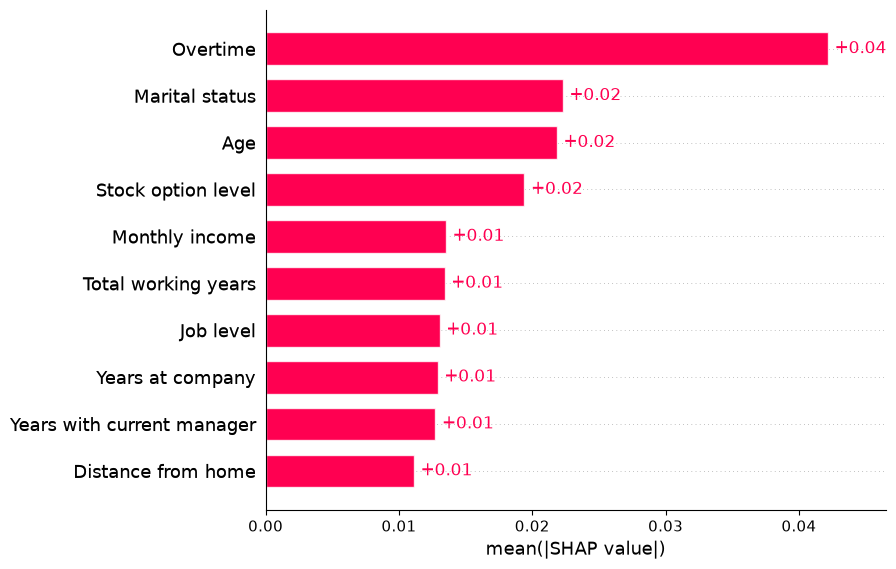

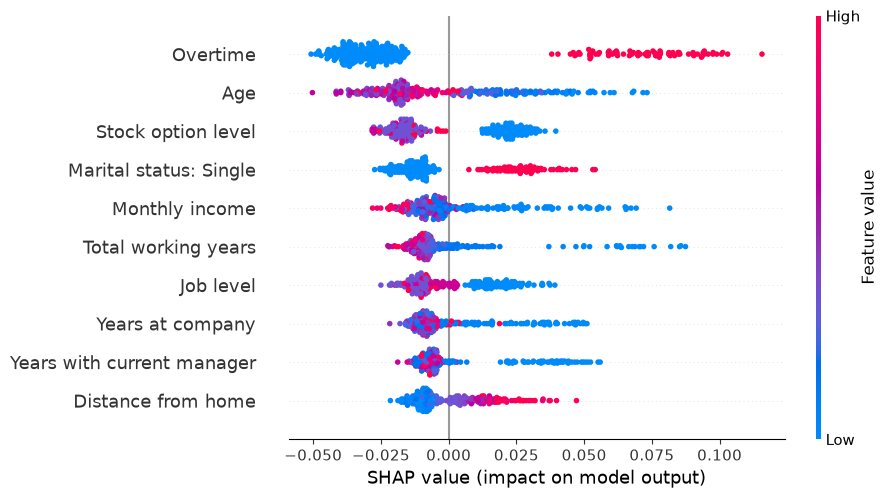

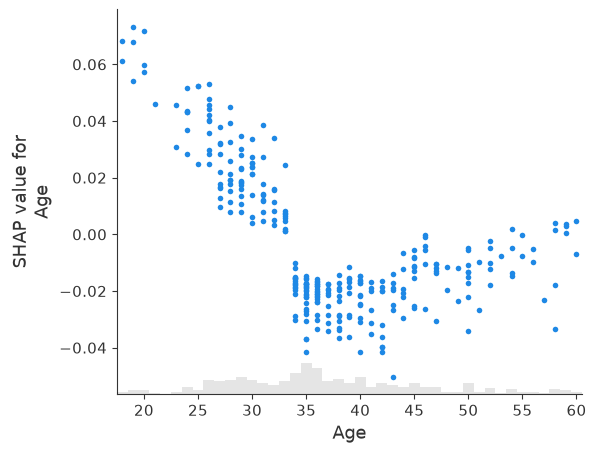

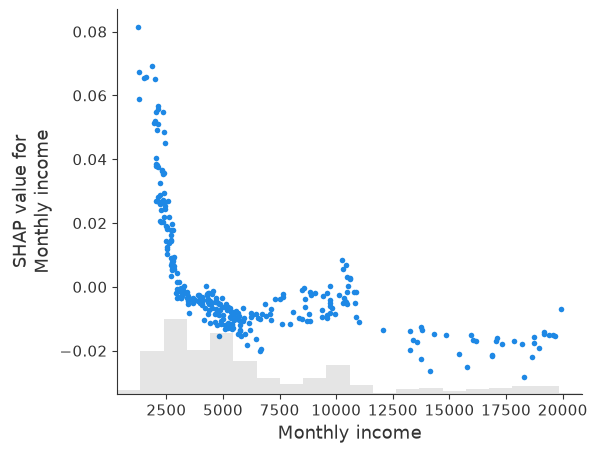

In [7]:
explain_globally(sv, groups)

**Interpretation:**

**Importance:** We see that overtime is by far the strongest driver of the prediction, with an influence about twice as high as the next feature. Marital status, age, stock option level, then career features such as salary, experience, hierarchy position, years in the company and years with the same manager also play a role. Gender hardly plays a role here.

**Direction:** Overtime (red) increases the risk. Singles and employees without stock options have a higher risk as well. Lower values in age, salary, hierarchy, work experience and tenure (blue on the right) also increase the risk, as well as a longer commute.

**Dependence:** The SHAP value of age and income drops steeply at first and then flattens out.

### 3.1 Tipping points

Average SHAP value per value range in percentage points. Positive = this range raises the predicted risk.

In [8]:
def effect_by_band(g, X, feature, edges):
    """Returns the average SHAP value of one feature per value band, in percentage points."""
    bands = pd.cut(X[feature], edges)
    effect = pd.Series(g[:, feature].values * 100, index=X.index)
    table = effect.groupby(bands, observed=True).agg(["mean", "size"]).round(1)
    return table.rename(columns={"mean": "avg effect (pp)", "size": "employees"})


def tipping_points(g, X):
    """Returns the band table for every feature in BANDS."""
    return pd.concat({readable(f): effect_by_band(g, X, f, edges) for f, edges in BANDS.items()})


tipping_points(groups, X_test)

avg effect (pp)  employees
Age                        (17, 25]                    5.1         20
                           (25, 30]                    2.5         56
                           (30, 35]                   -0.8         66
                           (35, 45]                   -2.3        101
                           (45, 60]                   -1.1         51
Monthly income             (1000, 2500]                4.0         45
                           (2500, 4000]                0.4         64
                           (4000, 6000]               -0.8         82
                           (6000, 10000]              -0.8         50
                           (10000, 20000]             -1.2         53
Total working years        (-1, 2]                     6.4         23
                           (2, 5]                      0.5         44
                           (5, 10]                    -0.8        108
                           (10, 20]                   -1.1         79
                           (20, 40]                   -1.2         40
Years at company           (-1, 1]                     3.7         41
                           (1, 3]                      0.6         50
                           (3, 5]                     -0.9         68
                           (5, 10]                    -1.0         80
                           (10, 40]                   -0.6         55
Years with current manager (-1, 0]                     3.7         55
                           (0, 2]                     -0.7         78
                           (2, 5]                     -0.8         56
                           (5, 17]                    -0.7        105
Distance from home         (0, 5]                     -1.0        124
                           (5, 10]                    -0.3         78
                           (10, 20]                    1.1         51
                           (20, 29]                    2.4         41

**Interpretation:**

The risk is highest in the following areas: age until 25, salary until 2,500, at most 2 total working years, maximal 1 year in the company itself, new manager (0 years). Each of these ranges adds +4 to +6 percentage points.

Above these ranges the effect drops quickly and turns negative for established employees. The longest commutes (over 20) add approximately 2 percentage points.

### 3.2 Which drivers can management act on?

Note: We don't focus on stock options, since all 470 singles are on level 0, so we cannot separate the effect from marital status.

Which features count as levers is our judgment (list `LEVERS` in the first code cell): overtime, pay, business travel and training are direct levers while job level, years with the current manager and satisfaction can only be influenced indirectly (promotions, manager changes, working conditions).

In [9]:
def impact(g):
    """Returns the average absolute SHAP value per feature in percentage points, highest first."""
    return pd.Series(np.abs(g.values).mean(0) * 100, index=g.feature_names).sort_values(ascending=False)


def share(g, features):
    """Returns the share of the total impact that comes from the given features."""
    total = impact(g)
    return total[total.index.isin(features)].sum() / total.sum()


def lever_table(g, k=10):
    """Returns the k strongest drivers with their average impact and whether management can act on them."""
    strongest = impact(g).head(k)
    return pd.DataFrame({"driver": [readable(f) for f in strongest.index],
                         "avg impact (pp)": strongest.round(1).values,
                         "management lever": strongest.index.isin(LEVERS)})


print(f"Share of the total impact management can act on: {share(groups, LEVERS):.0%}")
lever_table(groups)

Share of the total impact management can act on: 47%


,driver,avg impact (pp),management lever
0,Overtime,4.2,True
1,Marital status,2.2,False
2,Age,2.2,False
3,Stock option level,1.9,False
4,Monthly income,1.4,True
5,Total working years,1.3,False
6,Job level,1.3,True
7,Years at company,1.3,False
8,Years with current manager,1.3,True
9,Distance from home,1.1,False


**Interpretation:**

Under our classification, management levers account for 47% of the total impact. Since it includes indirect levers, this is an optimistic estimate.

Among the top ten are overtime, monthly income, hierarchy and years with current manager. These are factors that can be influenced by the management. Age, marital status and years at company are factors that cannot be influenced by the management, but show HR where to look, e.g. at new joiners.


## 4 Cross-checks

The following three checks provide us with more information on what actually helps:

- Permutation importance: we shuffle each feature 20 times and average the drop in average precision (AP). Recomputing this on 1,000 bootstrap samples of the test set gives a 95% interval that shows how much the result depends on which employees happen to be in the test set. Features whose interval lies above 0 are robust drivers.
- Fairness check: we retrain the forest once with all features and once without age, gender and marital status (personal features an employer should not base decisions on), on the same cross-validation folds, and compare the results pair by pair.
- Error rates by group (4.3): does the model treat age, gender and marital groups equally?

In [10]:
def weighted_ap(y, risk, weights):
    """Returns the average precision of one ranking for many bootstrap weightings of the test set at once."""
    order = np.argsort(-risk, kind="stable")
    last = np.r_[np.diff(risk[order]) != 0, True]
    tp = np.cumsum(weights[:, order] * y[order], axis=1)[:, last]
    flagged = np.cumsum(weights[:, order], axis=1)[:, last]
    precision = np.divide(tp, flagged, out=np.zeros(tp.shape), where=flagged > 0)
    return (np.diff(tp, axis=1, prepend=0) * precision).sum(1) / tp[:, -1]


def shuffle_risk(rf, X, columns, rng):
    """Returns the predicted risk after shuffling the given columns together."""
    shuffled = X.copy()
    shuffled[columns] = X[columns].values[rng.permutation(len(X))]
    return rf.predict_proba(shuffled)[:, 1]


def feature_columns(X):
    """Maps every original feature and the career block to the model columns that belong to it."""
    columns = {f: [c for c in X.columns if source_of(c) == f] for f in dict.fromkeys(map(source_of, X.columns))}
    return columns | {"Career stage": CAREER}


def check_weighted_ap(y, risk):
    """Stops if the fast average precision differs from scikit-learn's on the unweighted test set."""
    fast = weighted_ap(y, risk, np.ones((1, len(y))))[0]
    assert np.isclose(fast, average_precision_score(y, risk)), "weighted_ap does not match scikit-learn"


def permutation_impact(rf, X, y, shuffles=20, samples=1000):
    """Returns the AP drop per feature, averaged over shuffles, with its 95% interval over bootstrap samples."""
    rng = np.random.default_rng(SEED)
    y, risk = y.values, rf.predict_proba(X)[:, 1]
    check_weighted_ap(y, risk)
    weights = rng.multinomial(len(X), np.full(len(X), 1 / len(X)), size=samples)
    before = weighted_ap(y, risk, weights)
    drops = pd.DataFrame({f: before - np.mean([weighted_ap(y, shuffle_risk(rf, X, cols, rng), weights)
                                                for _ in range(shuffles)], axis=0)
                          for f, cols in feature_columns(X).items()}) * 100
    return pd.DataFrame({"mean": drops.mean(), "low": drops.quantile(0.025), "high": drops.quantile(0.975)})




def block_impact(g, features):
    """Returns the average absolute summed SHAP value of a block of features, in percentage points."""
    cols = [list(g.feature_names).index(f) for f in features]
    return np.abs(g.values[:, cols].sum(1)).mean() * 100


def compare_methods(g, permuted, k=10):
    """Returns SHAP impact, AP drop and its 95% interval for the k strongest drivers and the career block."""
    shap_impact = pd.concat([impact(g).head(k), pd.Series({"Career stage": block_impact(g, CAREER)})])
    p = permuted.loc[shap_impact.index]
    return pd.DataFrame({"driver": [readable(f) for f in shap_impact.index],
                         "SHAP impact (pp)": shap_impact.round(1).values,
                         "AP drop (points)": p["mean"].round(1).values,
                         "95% interval": [f"{lo:+.1f} to {hi:+.1f}" for lo, hi in zip(p["low"], p["high"])],
                         "robust": (p["low"] > 0).values})


def without(X, features):
    """Returns X without the columns that belong to the given features."""
    return X[[c for c in X.columns if source_of(c) not in features]]


def evaluate(rf, X_train, y_train, X_test, y_test):
    """Retrains the forest with identical settings and returns its AP on the shared folds and the test set."""
    cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)
    scores = cross_val_score(clone(rf), X_train, y_train, cv=cv, scoring="average_precision", n_jobs=-1)
    test = average_precision_score(y_test, clone(rf).fit(X_train, y_train).predict_proba(X_test)[:, 1])
    return scores, test


def paired_interval(diff, test_share=0.2):
    """Returns the 95% interval of a mean CV difference, widened for the overlapping training sets."""
    se = np.sqrt((1 / len(diff) + test_share / (1 - test_share)) * diff.var(ddof=1))
    half = stats.t.ppf(0.975, len(diff) - 1) * se
    return diff.mean() - half, diff.mean() + half


def fairness_check(rf, X_train, y_train, X_test, y_test, features):
    """Compares the forest with and without the given features on the same CV folds and on the test set."""
    full, full_test = evaluate(rf, X_train, y_train, X_test, y_test)
    cut, cut_test = evaluate(rf, without(X_train, features), y_train, without(X_test, features), y_test)
    low, high = paired_interval(full - cut)
    print(f"AP loss without the features, paired over the same {len(full)} folds: {(full - cut).mean():.3f} "
          f"(95% interval {low:+.3f} to {high:+.3f})")
    table = {"CV AP": [full.mean(), cut.mean()], "CV spread": [full.std(), cut.std()],
             "test AP": [full_test, cut_test]}
    return pd.DataFrame(table, index=["all features", "without sensitive features"]).round(3)

### 4.1 Permutation importance

In [11]:
compare_methods(groups, permutation_impact(rf, X_test, y_test))

,driver,SHAP impact (pp),AP drop (points),95% interval,robust
0,Overtime,4.2,9.6,+4.4 to +15.8,True
1,Marital status,2.2,-1.2,-4.8 to +2.5,False
2,Age,2.2,-3.5,-7.7 to +0.7,False
3,Stock option level,1.9,0.4,-2.1 to +2.8,False
4,Monthly income,1.4,2.5,-0.2 to +5.5,False
5,Total working years,1.3,-3.3,-7.3 to +0.4,False
6,Job level,1.3,0.4,-2.0 to +2.5,False
7,Years at company,1.3,-2.3,-5.4 to +0.7,False
8,Years with current manager,1.3,-2.5,-5.7 to +0.7,False
9,Distance from home,1.1,0.0,-2.4 to +2.1,False


**Interpretation:**

- Overtime is robust: shuffling it lowers AP by 9.6 points (95% interval +4.4 to +15.8).
- The seven career features shuffled together lower AP by 16.7 points (+7.7 to +26.9): career stage as a whole is a robust driver.
- No other single feature is confirmed. Monthly income just misses (-0.2 to +5.5).
- Negative values (age, working years) do not mean these features are useless. They share information with correlated features (income and job level correlate at 0.95), so the model compensates when one is shuffled.
- Stock options are not confirmed (-2.1 to +2.8).

### 4.2 Fairness check

In [12]:
print(f"Share of the total SHAP impact from age, gender and marital status: {share(groups, SENSITIVE):.0%}")
fairness_check(rf, X_train, y_train, X_test, y_test, SENSITIVE)

Share of the total SHAP impact from age, gender and marital status: 15%
AP loss without the features, paired over the same 15 folds: 0.020 (95% interval -0.015 to +0.056)


,CV AP,CV spread,test AP
all features,0.555,0.067,0.469
without sensitive features,0.535,0.070,0.575


**Interpretation:**

Removing age, gender and marital status lowers the cross-validated AP by 0.020 on average. Both versions are evaluated on the same 15 folds, so we compare them pair by pair. The 95% interval (−0.015 to +0.056) is widened because the folds share training data (corrected resampled t-test, Nadeau & Bengio 2003). It includes 0: there is no detectable loss, but a loss of up to about 0.06 cannot be ruled out. The higher test AP without them (0.575 vs. 0.469) rests on only 47 leavers and does not show that the reduced model is generally better.

At the same time, these features account for 15% of the explanation. Since they add no detectable accuracy, we recommend removing them before the model is used in practice.

- Stock options are not sensitive themselves, but they are tied to marital status and not confirmed in 4.1, so they should be reviewed as a proxy.
- This shows no detectable need for these features. It does not show that the model is fair; see 4.3.

### 4.3 Error rates by group

In [13]:
def group_of(X, feature):
    """Returns the group of every employee in X for one sensitive feature, age in three bands."""
    values = RAW.loc[X.index, feature]
    return pd.cut(values, AGE_GROUPS) if feature == "Age" else values


def flags(model, X, threshold=None):
    """Returns who the tuned model flags, at its own threshold or at a given one."""
    threshold = model.best_threshold_ if threshold is None else threshold
    return model.estimator_.predict_proba(X)[:, 1] >= threshold


def interval(hits, n, z=1.96):
    """Returns the 95% Wilson interval of a share as text, which stays honest for small groups."""
    centre = (hits + z**2 / 2) / (n + z**2)
    half = z * np.sqrt(hits * (n - hits) / n + z**2 / 4) / (n + z**2)
    return f"{centre - half:.2f}-{centre + half:.2f}"


def rates(d):
    """Returns size, attrition, flag rate, TPR and FPR of one group, the last two with 95% intervals."""
    leavers, stayers = d[d["left"] == 1], d[d["left"] == 0]
    caught, false_alarms = leavers["flagged"].sum(), stayers["flagged"].sum()
    return pd.Series({"employees": len(d), "leavers": len(leavers), "attrition rate": d["left"].mean(),
                      "flag rate": d["flagged"].mean(), "TPR": caught / len(leavers),
                      "TPR 95% CI": interval(caught, len(leavers)), "FPR": false_alarms / len(stayers),
                      "FPR 95% CI": interval(false_alarms, len(stayers))})


def group_rates(flagged, X, y, feature):
    """Returns the rates per group of one sensitive feature."""
    df = pd.DataFrame({"flagged": flagged, "left": y.values, "group": group_of(X, feature).values})
    return df.groupby("group", observed=True)[["flagged", "left"]].apply(rates)


def rates_by_group(flagged, X, y, features):
    """Returns the group rates for every sensitive feature in one table."""
    table = pd.concat({readable(f): group_rates(flagged, X, y, f) for f in features})
    numbers = {"employees": int, "leavers": int, "attrition rate": float, "flag rate": float,
               "TPR": float, "FPR": float}
    return table.astype(numbers).round(2)


def gaps(table):
    """Returns the largest difference between groups in flag rate, TPR and FPR per sensitive feature."""
    spread = table.groupby(level=0)[["flag rate", "TPR", "FPR"]].agg(lambda s: s.max() - s.min())
    return spread.rename(columns={"flag rate": "parity gap", "TPR": "TPR gap", "FPR": "FPR gap"})


rates_by_group(flags(model, X_test), X_test, y_test, SENSITIVE)


employees  leavers  attrition rate  flag rate   TPR  \
               group                                                           
Age            (17, 30]         76       17            0.22       0.33  0.65   
               (30, 45]        167       24            0.14       0.07  0.25   
               (45, 60]         51        6            0.12       0.06  0.33   
Gender         Female          119       13            0.11       0.13  0.46   
               Male            175       34            0.19       0.13  0.38   
Marital status Divorced         74       13            0.18       0.11  0.23   
               Married         126       16            0.13       0.07  0.31   
               Single           94       18            0.19       0.23  0.61   

                        TPR 95% CI   FPR FPR 95% CI  
               group                                 
Age            (17, 30]  0.41-0.83  0.24  0.15-0.36  
               (30, 45]  0.12-0.45  0.03  0.02-0.08  
               (45, 60]  0.10-0.70  0.02  0.00-0.12  
Gender         Female    0.23-0.71  0.09  0.05-0.17  
               Male      0.24-0.55  0.07  0.04-0.13  
Marital status Divorced  0.08-0.50  0.08  0.04-0.18  
               Married   0.14-0.56  0.04  0.01-0.09  
               Single    0.39-0.80  0.14  0.08-0.24

In [14]:
def variants(model, X_train, y_train, X_test, features):
    """Returns who is flagged by Jonas' model and by the pipeline without the features, at both thresholds."""
    reduced = clone(model).fit(without(X_train, features), y_train)
    print(f"Tuned threshold: {model.best_threshold_:.1%} with all features, "
          f"{reduced.best_threshold_:.1%} without")
    X_cut = without(X_test, features)
    return {"all features": flags(model, X_test), "without, own threshold": flags(reduced, X_cut),
            "without, Jonas' threshold": flags(reduced, X_cut, model.best_threshold_)}


def fairness_gaps(flagged, X, y, features):
    """Prints the share of flagged employees and returns the group gaps for every variant."""
    print(", ".join(f"{name}: {f.mean():.0%} flagged" for name, f in flagged.items()))
    table = {name: gaps(rates_by_group(f, X, y, features)) for name, f in flagged.items()}
    return pd.concat(table, axis=1).round(2)


fairness_gaps(variants(model, X_train, y_train, X_test, SENSITIVE), X_test, y_test, SENSITIVE)


Tuned threshold: 26.7% with all features, 22.2% without
all features: 13% flagged, without, own threshold: 25% flagged, without, Jonas' threshold: 17% flagged


all features                 without, own threshold          \
                 parity gap TPR gap FPR gap             parity gap TPR gap   
Age                    0.27    0.40    0.22                   0.22    0.17   
Gender                 0.00    0.08    0.02                   0.01    0.18   
Marital status         0.16    0.38    0.10                   0.13    0.05   

                       without, Jonas' threshold                  
               FPR gap                parity gap TPR gap FPR gap  
Age               0.18                      0.20    0.04    0.18  
Gender            0.01                      0.01    0.12    0.01  
Marital status    0.10                      0.10    0.18    0.09

**Interpretation:**

- Flag rate is the share of a group that the model flags (demographic parity). TPR is the share of leavers flagged (1 minus the false-negative rate). FPR is the share of stayers flagged. Equalized odds means equal TPR and FPR across groups.
- Jonas' model falsely flags 24% of stayers up to 30 (95% interval 15–36%), but only 3% aged 31–45 (2–8%). The intervals do not overlap, which implies a significant difference even with these small groups (non-overlap is a conservative test). Higher attrition among the young (22% vs. 12–14%) explains part of it, not its size.
- Singles show the same pattern (FPR 14% vs. 4% for married), but the intervals touch, so this is only indicative. For gender the intervals overlap almost completely: no evidence of a difference, though this does not prove equality.
- Some groups are too small to conclude anything: the TPR of 33% for ages 46–60 rests on 6 leavers (10–70%).
- Which fairness criterion to use is a normative choice. We do not aim for demographic parity, because attrition really differs by age. We use equalized odds, because both error types have a cost here: false alarms put stayers under suspicion, missed leavers cost the company.
- Without the sensitive features, the tuned threshold drops from 26.7% to 22.2%, so the model flags 25% instead of 13%. To separate this from the effect of the features, we also apply Jonas' threshold (17% flagged). Then the age TPR gap shrinks from 0.40 to 0.04, so leavers are found equally well at every age. The age FPR gap stays at 0.18: career features act as proxies for age.
- The remaining TPR gaps for gender and marital status (0.12–0.18) are within noise for groups of 13–18 leavers.

## 5 Local explanation: three employees

For our local case we use three persons: Leaver = left, with highest risk. Stayer = stayed with the lowest risk. Border case = very close to the decision threshold.

They are selected with pick_cases and pinned in CASES, so that the texts also fit the persons even after a new training of our model. The check stops the notebook if the rules no longer pick the same people.

In [15]:
def pick_cases(rf, X, y, threshold):
    """Proposes the clearest leaver, the clearest stayer and the employee closest to the threshold."""
    risk = pd.Series(rf.predict_proba(X)[:, 1], index=X.index)
    return {"Leaver": int(risk[y == 1].idxmax()), "Stayer": int(risk[y == 0].idxmin()),
            "Border case": int((risk - threshold).abs().idxmin())}


def check_cases(rf, X, y, threshold):
    """Prints the threshold and stops if the selection rules no longer pick the pinned cases."""
    print(f"Decision threshold: {threshold:.1%}")
    assert pick_cases(rf, X, y, threshold) == CASES, "the rules pick other people: update CASES and the texts"
    print("Rules still pick the pinned cases: True")


def describe_case(g, X, y, idx, threshold):
    """Prints risk, decision, outcome and the three strongest drivers in each direction for one employee."""
    row = g[X.index.get_loc(idx)]
    risk = row.base_values + row.values.sum()
    labels = [f"{readable(f)} = {v}" for f, v in zip(row.feature_names, row.display_data)]
    drivers = pd.Series(row.values * 100, index=labels)
    gap = (risk - threshold) * 100
    print(f"Employee #{RAW.loc[idx, 'EmployeeNumber']}: risk {risk:.1%} ({gap:+.1f} pp vs. threshold)"
          f" | flagged: {'yes' if gap >= 0 else 'no'} | actually left: {'yes' if y[idx] else 'no'}")
    print("Raises risk:", ", ".join(f"{k} ({v:+.1f} pp)" for k, v in drivers.nlargest(3).items()))
    print("Lowers risk:", ", ".join(f"{k} ({v:+.1f} pp)" for k, v in drivers.nsmallest(3).items()))


def plot_case(g, X, idx, name):
    """Waterfall plot: how each feature moves one employee from the average risk to their own risk."""
    shap.plots.waterfall(relabel(g)[X.index.get_loc(idx)], max_display=10, show=False)
    save(f"local_{name.lower().replace(' ', '_')}")


def explain_case(g, X, y, name, threshold):
    """Phase 5: prints the summary and draws the waterfall for one of the pinned employees."""
    describe_case(g, X, y, CASES[name], threshold)
    plot_case(g, X, CASES[name], name)


check_cases(rf, X_test, y_test, threshold)

Decision threshold: 26.7%
Rules still pick the pinned cases: True


### 5.1 Leaver

Employee #959: risk 79.7% (+53.0 pp vs. threshold) | flagged: yes | actually left: yes
Raises risk: Overtime = Yes (+9.4 pp), Total working years = 1 (+8.5 pp), Age = 19 (+6.8 pp)
Lowers risk: Business travel = Rarely (-1.0 pp), Environment satisfaction = Very high (-1.0 pp), Work life balance = Best (-0.2 pp)


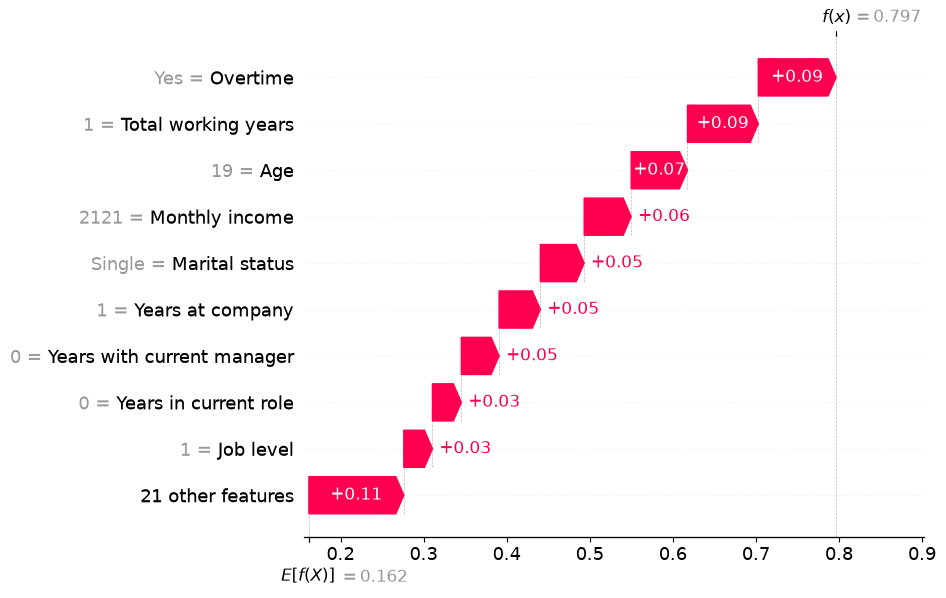

In [16]:
explain_case(groups, X_test, y_test, "Leaver", threshold)

**Interpretation:**

- First example: 19 years old, sales representative, in the first job year.
- Predicted risk 79.7%, 53 percentage points above the threshold.
- Overtime, only one year at the company, young age, low monthly income and single status: each feature adds 5 to 9 percentage points to the predicted risk.
- Nothing noticeably lowers the risk. The model is right, the person left the company.

### 5.2 Stayer

Employee #1658: risk 1.6% (-25.1 pp vs. threshold) | flagged: no | actually left: no
Raises risk: Years since last promotion = 7 (+0.6 pp), Training times last year = 2 (+0.3 pp), Job satisfaction = Medium (+0.2 pp)
Lowers risk: Overtime = No (-2.0 pp), Marital status = Divorced (-1.9 pp), Stock option level = 1 (-1.4 pp)


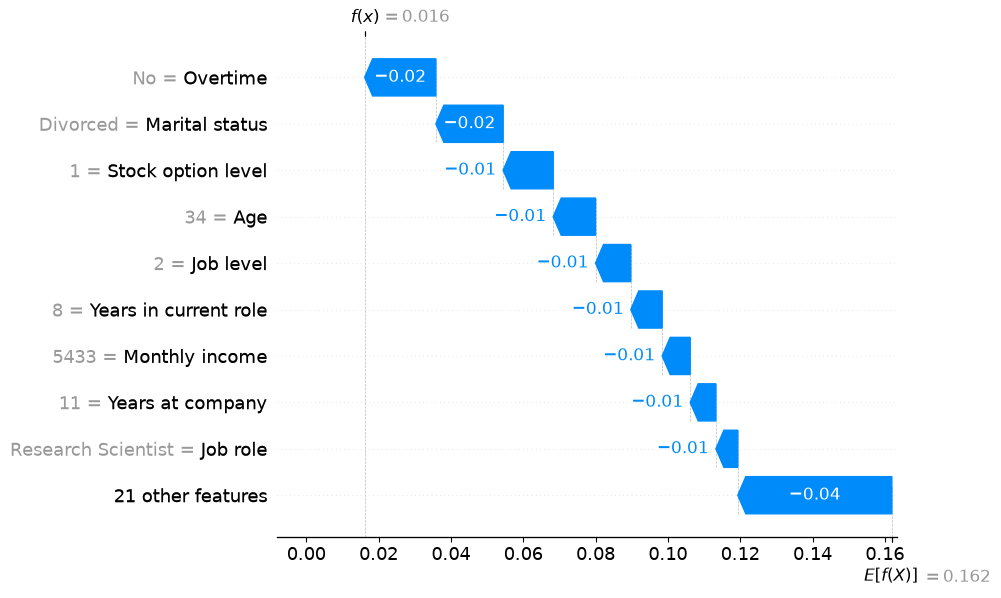

In [17]:
explain_case(groups, X_test, y_test, "Stayer", threshold)

**Interpretation:**

- 34 years old, research scientist, 11 years in the company, 9 years with the same manager.
- No overtime, divorced status, stock options and a stable role lower the risk. Nothing raises the risk noticeably.
- Predicted risk: 1.6%.
- The model's prediction is right: the person did not leave the company.

### 5.3 Border case

Employee #1645: risk 26.7% (+0.1 pp vs. threshold) | flagged: yes | actually left: yes
Raises risk: Overtime = Yes (+7.8 pp), Environment satisfaction = Low (+3.1 pp), Previous employers = 6 (+2.4 pp)
Lowers risk: Marital status = Divorced (-3.3 pp), Stock option level = 2 (-2.7 pp), Age = 35 (-1.9 pp)


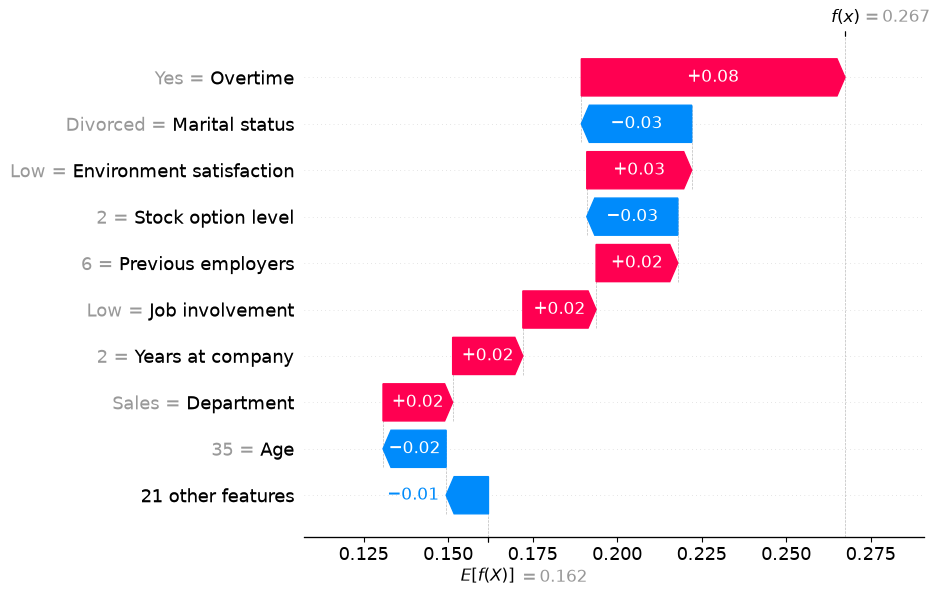

In [18]:
explain_case(groups, X_test, y_test, "Border case", threshold)

**Interpretation:**

- 35 years old, sales executive, 6 previous employers.
- Raising the risk: overtime, low environment satisfaction, many previous employers, low job involvement.
- Lowering the risk: divorced status, stock options, age.
- Starting from the base value of 16.2%, the features add +10.5 percentage points net.
- The predicted risk is 26.7%, only 0.1 pp above the threshold, so the model flags the person, and the person did leave.

This case shows how narrow a decision can be. HR should look at the risk score and its drivers, not only at the yes/no flag. Overtime and environment satisfaction are among the strongest drivers and are levers management can act on.

## 6 Managerial insights

1. Reduce overtime (3, 4.1, all three cases).
2. Strengthen retention in the first years (3.1, career block in 4.1).
3. Flexible or remote work for long commutes, as a pilot only: +2.4 pp for commutes over 20 (3.1), not confirmed in 4.1.
4. Measure environment satisfaction with short pulse surveys: driver in the border case (5.3), cheap to measure, not confirmed in 4.1.
5. Use the model as an early-warning ranking for conversations, never for decisions about individuals: it flags young and single employees far more often, also among those who stay (4.3).
6. Remove age, gender and marital status (4.2) and monitor error rates by group (4.3).

## 7 Limitations

- Correlation, not causation: SHAP can only explain our model. It cannot explain every aspect of real-world decisions.
- Removing features is not enough: even at the same threshold, the age gap in false alarms remains through proxies (4.3).
- Correlated features such as age, monthly income, hierarchy and work experience split their effect between them, so each one looks weaker than it is. Only the block is confirmed (4.1).
- The model finds only 19 of 47 leavers (recall 40%), so individual cases are tendencies.
- The explained model still uses age and marital status; a model without them would have to be explained again.
- The data are fictional (IBM sample dataset).